# 4.1 — Non-uniform random numbers

Functions live in `functions.py`; this notebook runs them and keeps the data and figures.

In [34]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

from functions import *

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [35]:
# Parameters (quote these in the report captions)
SEED = 1
N = 100_000      # number of samples per distribution
N_TRIES = 1_000_000  # random points thrown in hit-and-miss (about half or more are kept)
BINS = 50        # number of histogram bins

rng = np.random.default_rng(SEED)
set_plot_style()
info = f"N = {N:,} samples, {BINS} bins, seed = {SEED}"

## (0) Why the inverse CDF method works

**What we want to show:** take a uniform random number $u$ in $[0,1]$ and compute $x = F^{-1}(u)$.
Then $x$ has density $f$.

**Proof.** It is enough to show that $x$ has the right CDF, so that the chance of $x \le y$ is $F(y)$:

$$P(x \le y) \;=\; P\big(F^{-1}(u) \le y\big) \;=\; P\big(u \le F(y)\big) \;=\; F(y).$$

1. Fill in $x = F^{-1}(u)$.
2. Apply $F$ to both sides of the $\le$. This is allowed because $F$ only goes up.
3. A uniform number in $[0,1]$ lands below a value $c$ with chance $c$ (below $0.3$ with chance $0.3$, and so on).

So $x$ has CDF $F$, and taking the derivative gives the density $F'(y) = f(y)$. $\blacksquare$

**intuitive** $F$ climbs from 0 to 1. Pick a random height $u$ and read off the $x$ where $F$ reaches that height.
Where $f$ is large, $F$ is steep: many heights map onto a small stretch of $x$, so many numbers land there.

## (a) Inverse CDF: uniform, exponential, linear

For each density: integrate $f$ to get $F$, set $u = F(x)$ and solve for $x$.

| we want | $F(x)$ | so $x = F^{-1}(u)$ |
|---|---|---|
| uniform on $[-2,1]$: $f = 1/3$ | $(x+2)/3$ | $x = -2 + 3u$ |
| exponential: $f = e^{-x}$, $x\ge0$ | $1-e^{-x}$ | $x = -\log(1-u)$ |
| linear: $f = (x+1)/2$ on $[-1,1]$ | $(x+1)^2/4$ | $x = 2\sqrt{u} - 1$ |

In [36]:
u = rng.random(N)        # N uniform numbers in [0, 1)
x_uniform = -2 + 3 * u

u = rng.random(N)
x_exp = -np.log(1 - u)   # 1 - u is never 0, so the log is safe

u = rng.random(N)
x_linear = 2 * np.sqrt(u) - 1

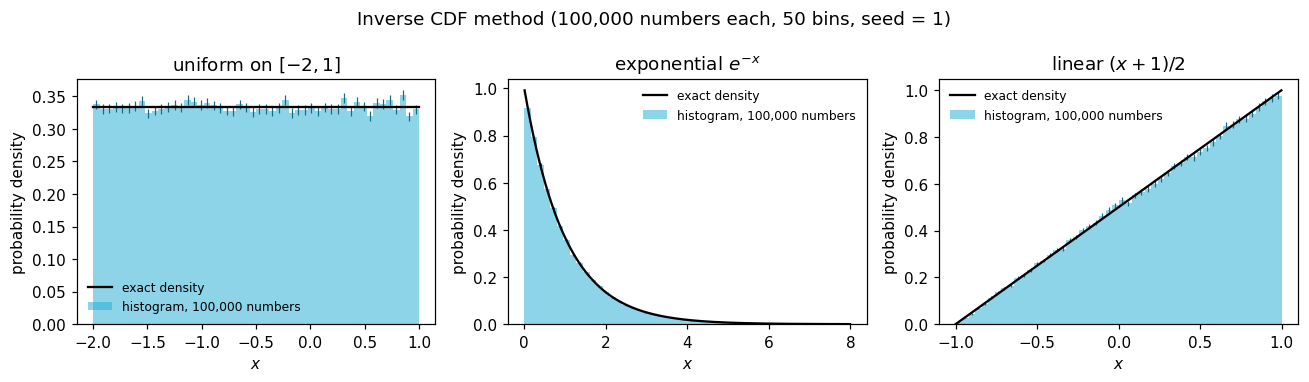

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))

plot_histogram(axes[0], x_uniform, lambda x: np.full_like(x, 1 / 3), -2, 1, BINS, "uniform on $[-2,1]$")
plot_histogram(axes[1], x_exp, lambda x: np.exp(-x), 0, 8, BINS, "exponential $e^{-x}$")
plot_histogram(axes[2], x_linear, lambda x: (x + 1) / 2, -1, 1, BINS, "linear $(x+1)/2$")

fig.suptitle(f"Inverse CDF method ({N:,} numbers each, {BINS} bins, seed = {SEED})")
fig.tight_layout()
save_figure(fig, "a_inverse_cdf")
plt.show()

## (b) Hit-and-miss: linear and $f(x) = -x(1-x)e^{-x^2}\log(1-x)$

Throw random points $(t, s)$ in a box around the graph of $f$: $t$ in $[a,b]$, $s$ in $[0,M]$, with $M$ at least the top of $f$.
Keep $t$ when the point lies under the curve ($s \le f(t)$).

The fraction we keep is (area under $f$) / (area of the box) $= \dfrac{\text{area under } f}{M(b-a)}$.

In [38]:
def hit_and_miss(f, a, b, M, n_tries):
    t = rng.uniform(a, b, n_tries)   # random position
    s = rng.uniform(0, M, n_tries)   # random height
    hit = s <= f(t)                  # True if the point lies under the curve
    return t[hit], hit.mean()        # the kept numbers, and the fraction kept

**Linear** $f = (x+1)/2$ on $[-1,1]$: the top is $f(1) = 1$, so $M = 1$.
The area under $f$ is 1, so we expect to keep $1/(1\cdot 2) = 1/2$ of the points.

In [39]:
x_linear_hm, kept_linear = hit_and_miss(lambda x: (x + 1) / 2, -1, 1, 1, N_TRIES)
print(f"kept {kept_linear:.4f} of the points (expected 0.5)")

kept 0.5007 of the points (expected 0.5)


**The second function** has no simple formula for its maximum or its area, so we let the computer find them:
$M$ from the largest value on a fine grid (plus 1% to be safe), and the area $Z$ with `quad` (integration from scipy).

Hit-and-miss only cares about the shape of $f$, so the area does not need to be 1.
We only divide by $Z$ when we draw $f$ on top of the histogram.

In [40]:
def f_weird(x):
    return -x * (1 - x) * np.exp(-x**2) * np.log(1 - x)

grid = np.linspace(0, 0.999, 10_000)
M = 1.01 * f_weird(grid).max()
Z, _ = quad(f_weird, 0, 1)

x_weird, kept_weird = hit_and_miss(f_weird, 0, 1, M, N_TRIES)
print(f"M = {M:.4f}, area Z = {Z:.5f}")
print(f"kept {kept_weird:.4f} of the points (expected Z / M = {Z / M:.4f})")

M = 0.1582, area Z = 0.09011
kept 0.5705 of the points (expected Z / M = 0.5697)


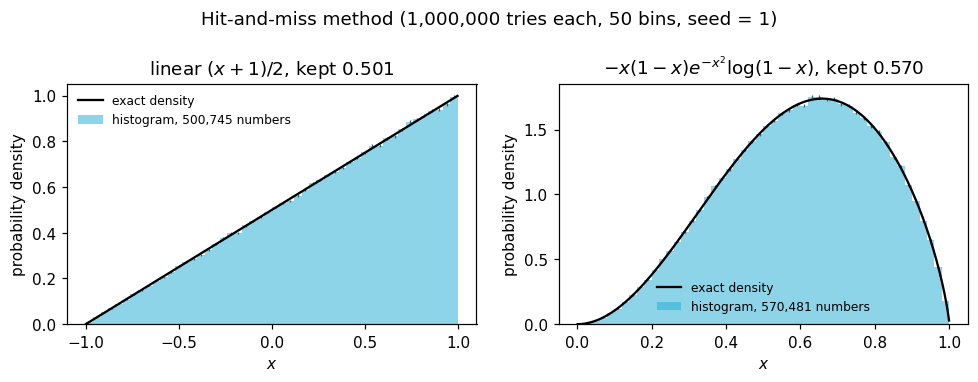

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))

plot_histogram(axes[0], x_linear_hm, lambda x: (x + 1) / 2, -1, 1, BINS,
               f"linear $(x+1)/2$, kept {kept_linear:.3f}")
plot_histogram(axes[1], x_weird, lambda x: f_weird(x) / Z, 0, 1, BINS,
               f"$-x(1-x)e^{{-x^2}}\\log(1-x)$, kept {kept_weird:.3f}")

fig.suptitle(f"Hit-and-miss method ({N_TRIES:,} tries each, {BINS} bins, seed = {SEED})")
fig.tight_layout()
save_figure(fig, "b_hit_and_miss")
plt.show()

To see what hit-and-miss actually does: throw some points in the box for the second function. The blue ones lie under the curve and are kept, the red ones lie above it and are thrown away.

<>:17: SyntaxWarning: invalid escape sequence '\l'
<>:17: SyntaxWarning: invalid escape sequence '\l'
C:\Users\Mathi\AppData\Local\Temp\ipykernel_4220\2318694005.py:17: SyntaxWarning: invalid escape sequence '\l'
  ax.set_title(f"Hit-and-miss for $-x(1-x)e^{{-x^2}}\log(1-x)$ ({n_show:,} points, seed = {SEED})", fontsize=9)


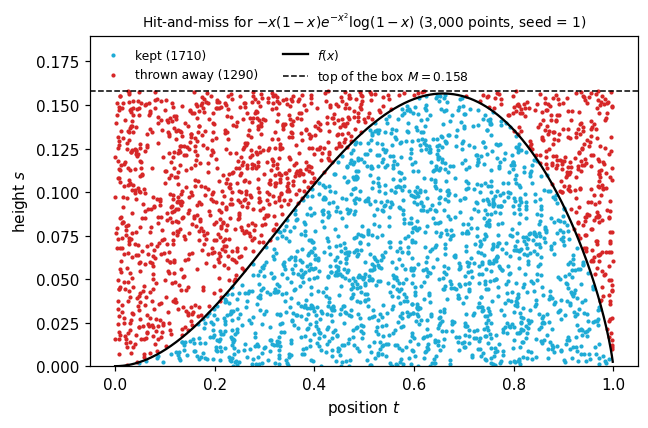

In [42]:
n_show = 3000
t = rng.uniform(0, 1, n_show)   # random position
s = rng.uniform(0, M, n_show)   # random height
hit = s <= f_weird(t)

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(t[hit], s[hit], s=3, color=KUL_BLUES[0], label=f"kept ({hit.sum()})")
ax.scatter(t[~hit], s[~hit], s=3, color="tab:red", label=f"thrown away ({(~hit).sum()})")

x = np.linspace(0, 0.999, 500)
ax.plot(x, f_weird(x), color="k", lw=1.5, label="$f(x)$")
ax.axhline(M, color="k", ls="--", lw=1, label=f"top of the box $M = {M:.3f}$")

ax.set_xlabel("position $t$")
ax.set_ylabel("height $s$")
ax.set_ylim(0, 1.2 * M)
ax.set_title(f"Hit-and-miss for $-x(1-x)e^{{-x^2}}\log(1-x)$ ({n_show:,} points, seed = {SEED})", fontsize=9)
ax.legend(frameon=False, fontsize=8, loc="upper left", ncol=2)
fig.tight_layout()
save_figure(fig, "b_hit_and_miss_points")
plt.show()

## (c) Hit-and-miss: uniform points in the unit disk

Throw points in the square $[-1,1]\times[-1,1]$ and keep the ones inside the circle ($x^2 + y^2 \le 1$).
We expect to keep (area circle)/(area square) $= \pi/4 \approx 0.785$ of them.

In [47]:
x = rng.uniform(-1, 1, N_TRIES)
y = rng.uniform(-1, 1, N_TRIES)
inside = x**2 + y**2 <= 1

x_hm, y_hm = x[inside], y[inside]
kept_disk = inside.mean()

# how much the kept fraction wobbles from run to run
error = np.sqrt(kept_disk * (1 - kept_disk) / N_TRIES)
print(f"kept {kept_disk:.4f} ± {error:.4f} of the points (expected pi/4 = {np.pi / 4:.4f})")
print(f"so pi is about {4 * kept_disk:.4f} ± {4 * error:.4f}")

kept 0.7853 ± 0.0004 of the points (expected pi/4 = 0.7854)
so pi is about 3.1410 ± 0.0016


## (d) Uniform disk without hit-and-miss (polar coordinates)

Pick each point as an angle $\theta$ and a distance $r$ from the centre.

- **Angle:** every direction is equally likely, so $\theta = 2\pi v$ with $v$ uniform.
- **Distance:** a circle at distance $r$ has length $2\pi r$, so there is more room far from the centre.
  The number of points at distance $r$ must grow like $r$: $f(r) = 2r$. Then $F(r) = r^2$, so $r = \sqrt{u}$.

(As a formula: $dA = r\,dr\,d\theta$, so $f(r,\theta) = \frac{r}{\pi} = 2r \cdot \frac{1}{2\pi}$.)

To see why the $\sqrt{\ }$ matters, we also make the **wrong** version with $r = u$.

In [48]:
theta = 2 * np.pi * rng.random(N)
r = np.sqrt(rng.random(N))
x_pol, y_pol = r * np.cos(theta), r * np.sin(theta)

# wrong on purpose: r uniform
theta = 2 * np.pi * rng.random(N)
r = rng.random(N)
x_wrong, y_wrong = r * np.cos(theta), r * np.sin(theta)

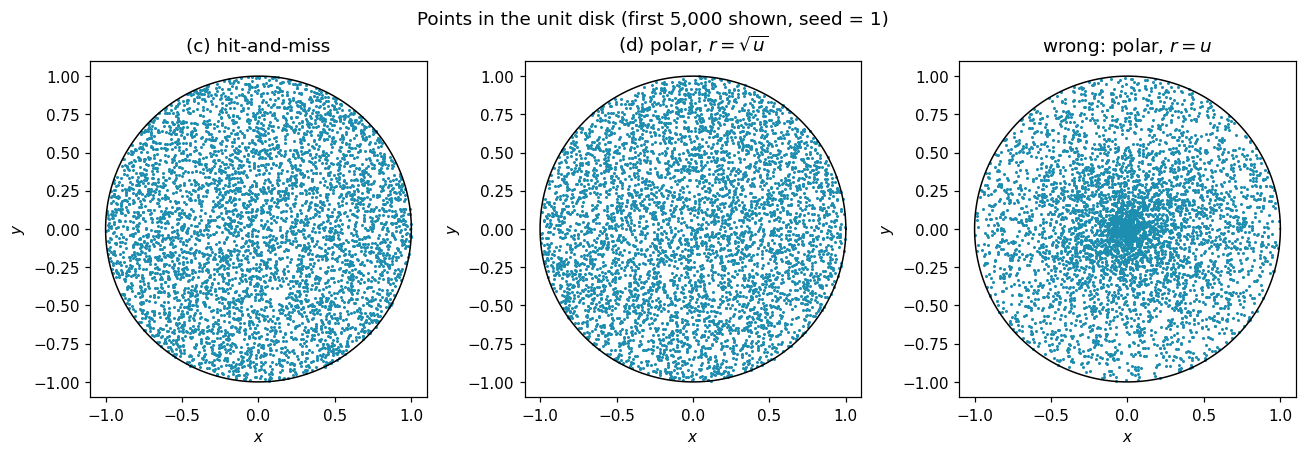

In [49]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
circle = np.linspace(0, 2 * np.pi, 400)
panels = [(x_hm, y_hm, "(c) hit-and-miss"),
          (x_pol, y_pol, r"(d) polar, $r=\sqrt{u}$"),
          (x_wrong, y_wrong, r"wrong: polar, $r=u$")]

for ax, (x, y, title) in zip(axes, panels):
    ax.scatter(x[:5000], y[:5000], s=1, color=KUL_BLUES[1])   # 5000 points, otherwise it is one blue blob
    ax.plot(np.cos(circle), np.sin(circle), color="k", lw=1)
    ax.set_aspect("equal")
    ax.set_xlabel("$x$")
    ax.set_ylabel("$y$")
    ax.set_title(title)

fig.suptitle(f"Points in the unit disk (first 5,000 shown, seed = {SEED})")
fig.tight_layout()
save_figure(fig, "cd_disk_scatter")
plt.show()

By eye the right panel is clearly wrong. To check it properly: make a histogram of the distances $r$. For points spread evenly over the disk it should follow $2r$.

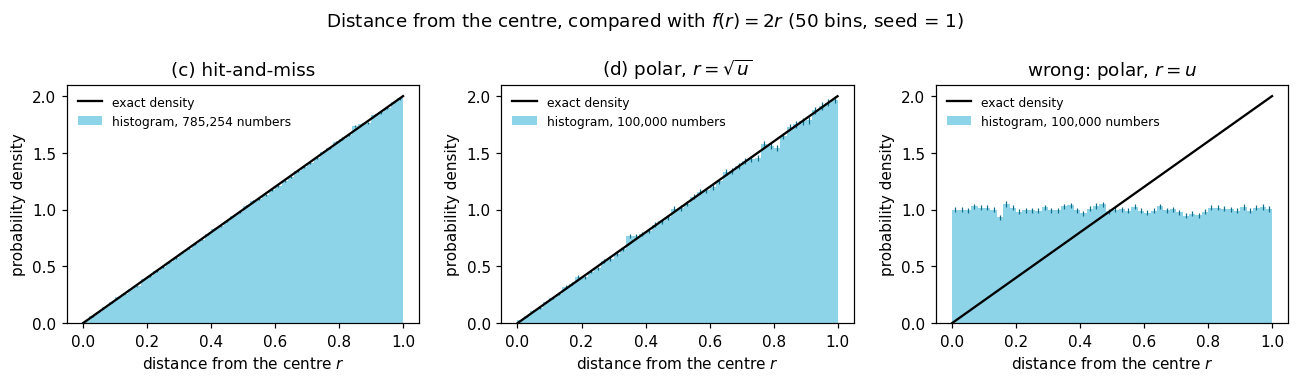

In [50]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
panels = [(x_hm, y_hm, "(c) hit-and-miss"),
          (x_pol, y_pol, r"(d) polar, $r=\sqrt{u}$"),
          (x_wrong, y_wrong, r"wrong: polar, $r=u$")]

for ax, (x, y, title) in zip(axes, panels):
    r = np.sqrt(x**2 + y**2)
    plot_histogram(ax, r, lambda r: 2 * r, 0, 1, BINS, title)
    ax.set_xlabel("distance from the centre $r$")

fig.suptitle(f"Distance from the centre, compared with $f(r) = 2r$ ({BINS} bins, seed = {SEED})")
fig.tight_layout()
save_figure(fig, "cd_radial_density")
plt.show()